# 05 · Method research, P3: monitoring without labels

Findings behind this step ([`reports/data_analysis.md`](../reports/data_analysis.md), D and F):
- a **step change** in the missing rate of V blocks at week 4;
- **browser-release spikes** of new `id_31` values in weeks 9 and 22 (and a smaller bump around week 18);
- a natural week-to-week fraud rate of 1.9-5.1%;
- 14 missing-together blocks and heavy redundancy.

**Design.** Each week 4-25 of the labelled data is compared with the 4 weeks just before it (rolling reference). The known events give a partial ground truth: a good monitor alarms in weeks 4, 9 and 22 and rarely elsewhere. Alarms outside these weeks are *not necessarily false*, since there may be changes the analysis did not find, so they are reported as "other alarms". Thresholds come from `configs/monitoring.yaml`, **not tuned**.

| | Candidate | Alarm rule |
|---|---|---|
| M1 | KS test per numeric column | any column with p < 0.05 |
| M2 | PSI, rule-of-thumb threshold | any column with PSI > 0.25 |
| M3 | PSI with asymptotic p-value, BH-FDR and an effect-size floor | any column significant after FDR **and** PSI > 0.1 |
| M4 | Categorical: JS divergence + chi-square, BH-FDR and effect floor | any column significant **and** JS > 0.02 nats |
| M5 | Missing rate per V block | any block significant **and** shift > 10 points |
| M6 | Domain classifier (current week vs reference) | out-of-fold AUC > 0.6 |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from fraud.analysis import near_constant
from fraud.config import load_config
from fraud.data import ENTITY_COL, ID_COL, PROCESSED_DIR, TARGET, TIME_COL, load_dataset
from fraud.drift import ks_pvalue, psi, psi_pvalue, rolling_monitor
from fraud.evaluate import average_precision
from fraud.features import is_categorical
from fraud.profiling import column_group, missing_blocks

cfg = load_config("monitoring")
FIG_DIR = Path("../reports/figures")
EVENTS = {4: "V-block missing step", 9: "browser release", 22: "browser release"}

df = load_dataset("train")
inputs = [c for c in df.columns if c not in (ID_COL, TARGET, TIME_COL, "timestamp", "day", "week", "month", ENTITY_COL)]
constant = set(near_constant(df, inputs).index)
numeric = [c for c in inputs if not is_categorical(df[c]) and c not in constant]
categorical = [c for c in inputs if is_categorical(df[c]) and c not in constant]
V = [c for c in inputs if column_group(c) == "V1-V339"]
block_columns = {f"{b['first']}-{b['last']}": b["first"] for _, b in missing_blocks(df, V).iterrows()}
print(f"monitored: {len(numeric)} numeric, {len(categorical)} categorical, {len(block_columns)} V blocks "
      f"({len(constant)} near-constant columns left out)")

monitored: 378 numeric, 29 categorical, 14 V blocks (24 near-constant columns left out)


## Are the PSI p-values valid?

Under "nothing changed", p-values should be uniform. Check on real data: split one week's transactions at random into two halves and test every numeric column. KS is valid too; its problem is power at large n, not validity.

same-week random halves (10,353 vs 10,507 rows): share of p < 0.05 -> PSI test 1.1%, KS 0.0%; columns with PSI > 0.1: 0, > 0.25: 0


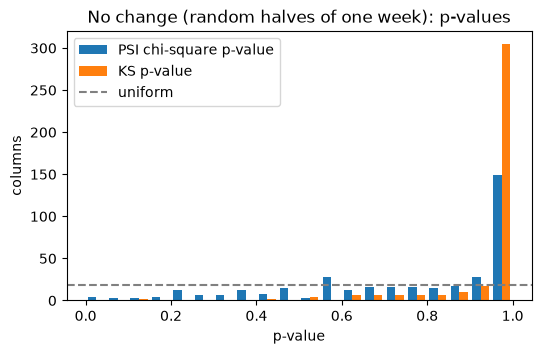

In [2]:
rng = np.random.default_rng(0)
week = df[df["week"] == 10]
half = rng.random(len(week)) < 0.5
a, b = week[half], week[~half]
null = []
for col in numeric:
    value, k = psi(a[col], b[col], cfg["psi"]["n_bins"], cfg["psi"]["epsilon"])
    null.append({"col": col, "psi": value,
                 "psi_p": psi_pvalue(value, a[col].notna().sum(), b[col].notna().sum(), k),
                 "ks_p": ks_pvalue(a[col], b[col])})
null = pd.DataFrame(null)
print(f"same-week random halves ({len(a):,} vs {len(b):,} rows): share of p < 0.05 -> PSI test {(null['psi_p'] < .05).mean():.1%}, "
      f"KS {(null['ks_p'] < .05).mean():.1%}; columns with PSI > 0.1: {(null['psi'] > .1).sum()}, > 0.25: {(null['psi'] > .25).sum()}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist([null["psi_p"], null["ks_p"]], bins=20, range=(0, 1), label=["PSI chi-square p-value", "KS p-value"])
ax.axhline(len(null) / 20, color="gray", ls="--", label="uniform")
ax.set(xlabel="p-value", ylabel="columns", title="No change (random halves of one week): p-values")
ax.legend()
fig.savefig(FIG_DIR / "mr_psi_null_check.png", dpi=120, bbox_inches="tight")

## Rolling weekly monitor, weeks 4-25

In [3]:
weeks = list(range(cfg["reference_weeks"], 26))  # week 26 is partial
mon = rolling_monitor(df, numeric, categorical, block_columns, cfg, weeks=weeks)
mon[["ks_flagged", "psi_fixed_flagged", "psi_test_flagged", "top_psi", "cat_flagged", "cat_max_js", "cat_top",
     "max_new_share", "blocks_flagged", "max_block_shift", "domain_auc", "domain_js_estimate"]]

,ks_flagged,psi_fixed_flagged,psi_test_flagged,top_psi,cat_flagged,cat_max_js,cat_top,max_new_share,blocks_flagged,max_block_shift,domain_auc,domain_js_estimate
week,,,,,,,,,,,,
4,230,12,21,"V151, V143, V166",5,0.048489,id_31,0.030594,11,0.246093,0.752136,0.129463
5,247,16,22,"V151, V160, V144",6,0.053833,ProductCD,0.034296,11,0.248919,0.737377,0.11623
6,211,6,17,"V302, C8, V303",6,0.072852,id_38,0.02113,10,0.257856,0.779469,0.153629
7,238,0,10,"C4, V302, V304",4,0.068048,id_30,0.030827,10,0.16192,0.75655,0.121628
8,78,0,2,"id_13, id_01, V164",4,0.061101,id_38,0.03837,0,0.035639,0.708679,0.084184
9,100,0,0,"id_13, id_01, dist2",4,0.165007,id_31,0.186119,0,0.0741,0.745247,0.115095
10,133,1,1,"id_13, id_02, V26",3,0.15781,id_31,0.036296,0,0.06133,0.734888,0.106352
11,89,1,1,"id_13, id_02, card5",3,0.097921,id_31,0.053641,0,0.080674,0.750445,0.123423
12,71,1,1,"id_13, id_02, card5",3,0.063257,id_31,0.048953,0,0.054191,0.735223,0.107122


In [4]:
alarms = pd.DataFrame({
    "M1 KS": mon["ks_flagged"] > 0,
    "M2 PSI > 0.25": mon["psi_fixed_flagged"] > 0,
    "M3 PSI test + effect": mon["psi_test_flagged"] > 0,
    "M4 categorical": mon["cat_flagged"] > 0,
    "M5 V-block missing": mon["blocks_flagged"] > 0,
    "M6 domain classifier": mon["domain_auc"].astype(float) > cfg["domain_classifier"]["alarm_auc"],
})
event_weeks = list(EVENTS)
score = pd.DataFrame({
    "alarms": alarms.sum(),
    **{f"week {w} ({name})": alarms.loc[w] for w, name in EVENTS.items()},
    "other alarms (of 19 weeks)": alarms.drop(index=event_weeks).sum(),
})
score

,alarms,week 4 (V-block missing step),week 9 (browser release),week 22 (browser release),other alarms (of 19 weeks)
M1 KS,22,True,True,True,19
M2 PSI > 0.25,14,True,False,False,13
M3 PSI test + effect,18,True,False,False,17
M4 categorical,22,True,True,True,19
M5 V-block missing,7,True,False,False,6
M6 domain classifier,22,True,True,True,19


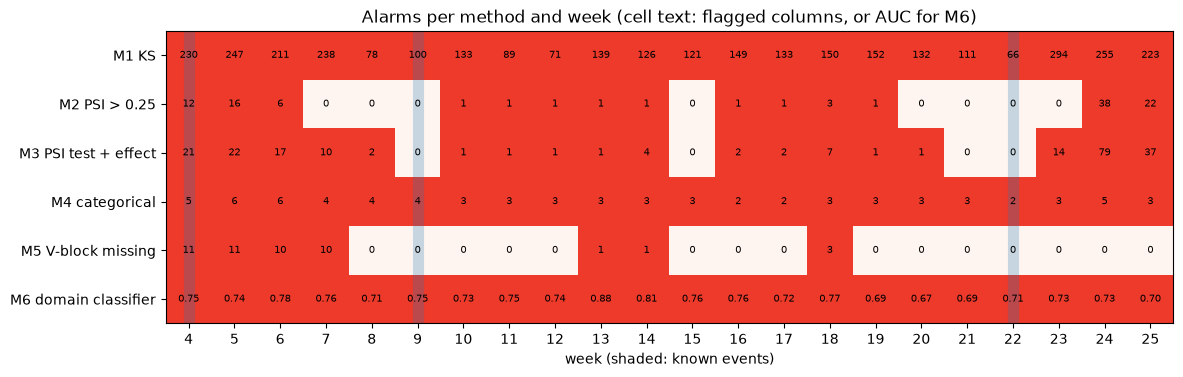

In [5]:
counts = mon[["ks_flagged", "psi_fixed_flagged", "psi_test_flagged", "cat_flagged", "blocks_flagged"]].astype(float)
counts["domain_auc"] = mon["domain_auc"].astype(float)
fig, ax = plt.subplots(figsize=(13, 3.8))
im = ax.imshow(alarms.T.astype(int), cmap="Reds", aspect="auto", vmin=0, vmax=1.6)
ax.set_xticks(range(len(alarms)), alarms.index)
ax.set_yticks(range(alarms.shape[1]), alarms.columns)
labels = [counts["ks_flagged"], counts["psi_fixed_flagged"], counts["psi_test_flagged"], counts["cat_flagged"],
          counts["blocks_flagged"], counts["domain_auc"]]
for i, values in enumerate(labels):
    for j, v in enumerate(values):
        ax.annotate(f"{v:.2f}" if i == 5 else f"{int(v)}", (j, i), ha="center", va="center", fontsize=7)
for w in event_weeks:
    ax.axvline(alarms.index.get_loc(w), color="C0", lw=8, alpha=.25)
ax.set(xlabel="week (shaded: known events)", title="Alarms per method and week (cell text: flagged columns, or AUC for M6)")
fig.savefig(FIG_DIR / "mr_monitor_alarms.png", dpi=120, bbox_inches="tight")

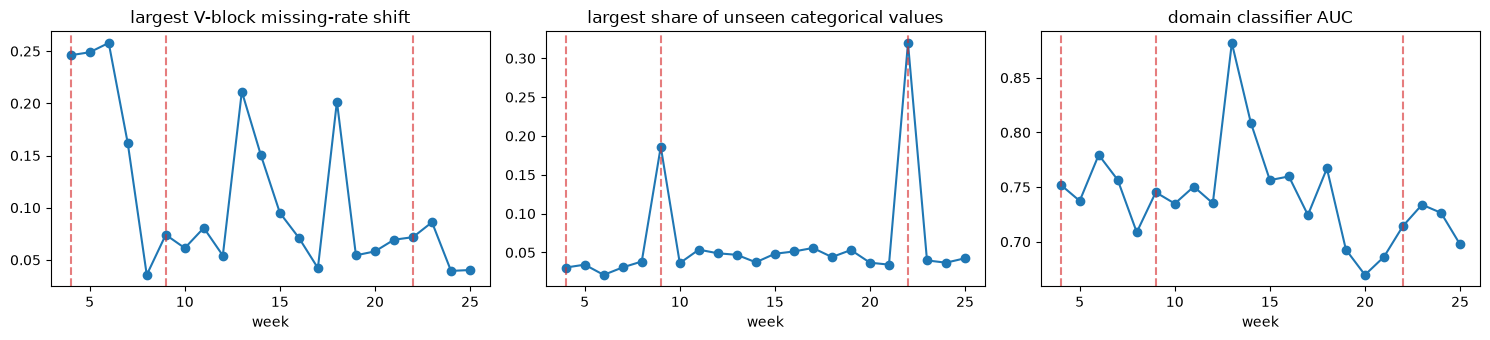

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5))
signals = [("max_block_shift", "largest V-block missing-rate shift"), ("max_new_share", "largest share of unseen categorical values"),
           ("domain_auc", "domain classifier AUC")]
for ax, (col, title) in zip(axes, signals):
    ax.plot(mon.index, mon[col].astype(float), marker="o")
    for w in event_weeks:
        ax.axvline(w, color="C3", ls="--", alpha=.6)
    ax.set(title=title, xlabel="week")
fig.tight_layout()
fig.savefig(FIG_DIR / "mr_monitor_signals.png", dpi=120, bbox_inches="tight")

## Preliminary: score drift and performance estimated without labels (CBPE)

Weeks 16-26, scored by the reference model and calibrated with isotonic regression (notebook 04). The calibrator was fitted on weeks 16-19, so those weeks are in-sample; only weeks 20-26 (7 points) are an honest check. **Not conclusive.**

In [7]:
s = pd.read_parquet(PROCESSED_DIR / "scores_p2.parquet")
ref_scores = s.loc[s["week"] <= 19, "score"]
rows = {}
for w, g in s.groupby("week"):
    top = g.nlargest(max(1, int(0.02 * len(g))), "p_isotonic")
    rows[w] = {
        "estimated_fraud_rate": g["p_isotonic"].mean(), "observed_fraud_rate": g[TARGET].mean(),
        "estimated_precision_top2pct": top["p_isotonic"].mean(), "observed_precision_top2pct": top[TARGET].mean(),
        "score_psi_vs_weeks_16_19": psi(ref_scores, g["score"])[0],
        "observed_pr_auc": average_precision(g[TARGET], g["score"]),
    }
cbpe = pd.DataFrame(rows).T.rename_axis("week")
honest = cbpe.loc[20:]
print("weeks 20-26: correlation of estimated vs observed weekly fraud rate "
      f"{np.corrcoef(honest['estimated_fraud_rate'], honest['observed_fraud_rate'])[0, 1]:.2f}; "
      f"mean absolute error {np.mean(np.abs(honest['estimated_fraud_rate'] - honest['observed_fraud_rate'])):.4f}")
cbpe.round(4)

weeks 20-26: correlation of estimated vs observed weekly fraud rate 0.79; mean absolute error 0.0033


,estimated_fraud_rate,observed_fraud_rate,estimated_precision_top2pct,observed_precision_top2pct,score_psi_vs_weeks_16_19,observed_pr_auc
week,,,,,,
16,0.0504,0.0506,0.9152,0.9643,0.0079,0.7296
17,0.0396,0.0368,0.8957,0.8803,0.0008,0.6710
18,0.0351,0.0353,0.8318,0.7985,0.0018,0.6098
19,0.0315,0.0346,0.7292,0.7527,0.0031,0.5724
20,0.0319,0.0359,0.7382,0.6667,0.0025,0.4899
21,0.0346,0.0317,0.7757,0.7420,0.0005,0.5748
22,0.0315,0.0285,0.6932,0.6159,0.0008,0.5224
23,0.0349,0.0325,0.7705,0.6316,0.0007,0.5073
24,0.0358,0.0367,0.7828,0.7178,0.0036,0.5529


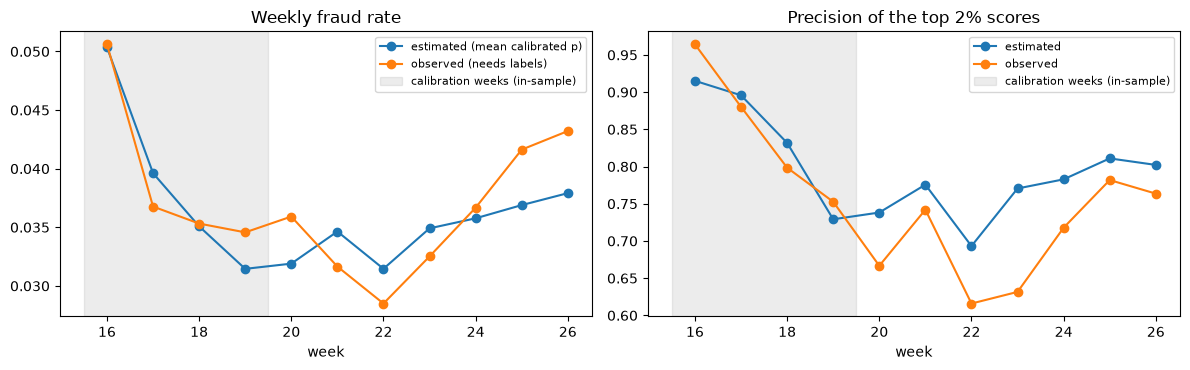

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].plot(cbpe.index, cbpe["estimated_fraud_rate"], marker="o", label="estimated (mean calibrated p)")
axes[0].plot(cbpe.index, cbpe["observed_fraud_rate"], marker="o", label="observed (needs labels)")
axes[0].set(title="Weekly fraud rate", xlabel="week")
axes[1].plot(cbpe.index, cbpe["estimated_precision_top2pct"], marker="o", label="estimated")
axes[1].plot(cbpe.index, cbpe["observed_precision_top2pct"], marker="o", label="observed")
axes[1].set(title="Precision of the top 2% scores", xlabel="week")
for ax in axes:
    ax.axvspan(15.5, 19.5, color="gray", alpha=.15, label="calibration weeks (in-sample)")
    ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "mr_cbpe.png", dpi=120, bbox_inches="tight")